# Project EcoDrive
## An End-to-End ML Pipeline for Pre-Owned EV Valuation & Market Demand Intelligence

**Role:** Lead ML Engineer, EcoDrive Mobility

**Dual objective**
1. **Classification** – predict `High_Demand` (0/1): will a listing sell fast?
2. **Regression** – forecast the fair `Resale_Price_USD`.

**Modules**
| # | Module | Techniques |
|---|--------|-----------|
| 1 | Exploration, wrangling, cleaning | Null audit, median/mode imputation, IQR outliers |
| 2 | Feature engineering, encoding, scaling | Energy Efficiency Index, degradation metrics, One-Hot, StandardScaler |
| 3 | Feature selection & validation | RFE, Stratified K-Fold |
| 4 | Tuning & baselines | Logistic Reg., KNN, SVM, RandomizedSearchCV |
| 5 | Ensembles & final evaluation | Random Forest (bagging), AdaBoost (boosting), model comparison |

> **Data note:** no raw dealership feed was supplied with the brief, so Section 0 generates a *synthetic but realistic* dataset
> that reproduces every data-quality problem described (missing inspection values, 9,999,999 km odometers, inflated prices, text categoricals,
> mixed scales). If you have the real file, replace Section 0 with `df_raw = pd.read_csv("your_file.csv")` – the rest of the pipeline is unchanged.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import RFE
from sklearn.model_selection import (StratifiedKFold, KFold, cross_validate,
                                     RandomizedSearchCV, train_test_split)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              AdaBoostClassifier, AdaBoostRegressor)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_squared_error, mean_absolute_error)
from scipy.stats import randint, loguniform

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="viridis")
os.makedirs("figures", exist_ok=True)
print("Libraries loaded.")

Libraries loaded.


## 0. Data Acquisition (synthetic EV dealership feed)
The generator encodes real-world relationships (depreciation with age, battery health loss, brand premium, region effects) and then
**deliberately corrupts** the data: ~3–6 % missing values, impossible odometer readings and inflated price typos.

In [2]:
def generate_ev_data(n=620, seed=SEED):
    rng = np.random.default_rng(seed)
    brands = ["Tesla", "Nissan", "Hyundai", "Kia", "Chevrolet", "BMW", "Volkswagen", "Tata", "BYD", "MG"]
    p_brand = [0.18, 0.12, 0.11, 0.10, 0.09, 0.08, 0.09, 0.09, 0.07, 0.07]
    cap_mean = dict(zip(brands, [75, 40, 64, 64, 60, 80, 62, 30, 60, 50]))
    premium = dict(zip(brands, [14000, 0, 5000, 4500, 3000, 17000, 5500, -2500, 2500, 0]))
    popularity = dict(zip(brands, [0.7, 0.1, 0.3, 0.3, 0.0, 0.2, 0.1, 0.4, 0.3, 0.0]))
    region_f = {"North America": 1.05, "Europe": 1.00, "Asia": 0.93, "Middle East": 0.97}

    brand = rng.choice(brands, n, p=p_brand)
    chem = rng.choice(["NMC", "LFP", "NCA"], n, p=[0.50, 0.35, 0.15])
    region = rng.choice(list(region_f), n, p=[0.30, 0.30, 0.28, 0.12])
    year = rng.choice(np.arange(2015, 2026), n, p=np.array([1, 1, 2, 3, 4, 6, 8, 10, 12, 14, 15]) / 76)
    age = 2026 - year

    capacity = np.clip(np.round(rng.normal([cap_mean[b] for b in brand], 8)), 25, 105)
    range_km = capacity * rng.normal(6.2, 0.7, n) + np.where(brand == "Tesla", 40, 0)
    odometer = np.clip(age * rng.uniform(6000, 22000, n), 1500, None)
    health = 100 - age * rng.normal(2.2, 0.5, n) - odometer / 1e5 * rng.normal(2, 0.5, n) + np.where(chem == "LFP", 3, 0)
    health = np.clip(health, 58, 100)
    charge = np.clip(rng.normal(np.where(np.isin(brand, ["Tesla", "BMW", "Hyundai", "Kia"]), 140, 80), 35), 22, 250)

    new_price = 12000 + capacity * 430 + np.array([premium[b] for b in brand])
    fair = (new_price * np.exp(-0.075 * age) * (0.6 + 0.4 * (health - 58) / 42)
            * (1 - odometer / 600000) * np.array([region_f[r] for r in region])
            * np.where(chem == "LFP", 0.97, 1.0))
    price = fair * np.exp(rng.normal(0, 0.05, n))

    log_ratio = np.log(price / fair)
    z = (0.06 * (health - 85) - 0.15 * (age - 5) - 12 * log_ratio + 0.01 * (charge - 100)
         + np.array([popularity[b] for b in brand]) + rng.logistic(0, 0.35, n))
    demand = (z > np.quantile(z, 0.62)).astype(int)

    df = pd.DataFrame({
        "Listing_ID": [f"EV{1000 + i}" for i in range(n)],
        "Brand": brand, "Model_Year": year, "Battery_Chemistry": chem, "Region": region,
        "Battery_Capacity_kWh": capacity.round(1), "Range_km": range_km.round(0),
        "Odometer_km": odometer.round(0), "Battery_Health_Pct": health.round(1),
        "Charging_Speed_kW": charge.round(0), "Resale_Price_USD": price.round(0),
        "High_Demand": demand})

    # ---- inject data-quality problems ----
    def nullify(col, frac):
        df.loc[rng.choice(n, int(frac * n), replace=False), col] = np.nan
    for col, frac in [("Battery_Health_Pct", .06), ("Charging_Speed_kW", .05), ("Odometer_km", .04),
                      ("Battery_Capacity_kWh", .03), ("Resale_Price_USD", .02),
                      ("Brand", .02), ("Battery_Chemistry", .03), ("Region", .02)]:
        nullify(col, frac)
    df.loc[rng.choice(n, 6, replace=False), "Odometer_km"] = 9_999_999            # impossible odometer
    df.loc[rng.choice(n, 8, replace=False), "Resale_Price_USD"] *= rng.uniform(3, 6, 8)  # inflated price typos
    df.loc[rng.choice(n, 3, replace=False), "Charging_Speed_kW"] = 900                # sensor glitch
    return df

df_raw = generate_ev_data()
df_raw.to_csv("ecodrive_raw_dataset.csv", index=False)
print(df_raw.shape)
df_raw.head(8)

(620, 12)


,Listing_ID,Brand,Model_Year,Battery_Chemistry,Region,Battery_Capacity_kWh,Range_km,Odometer_km,Battery_Health_Pct,Charging_Speed_kW,Resale_Price_USD,High_Demand
0,EV1000,Tata,2023,LFP,Asia,30.0,205.0,34503.0,95.3,26.0,15191.000000,0
1,EV1001,Kia,2025,NMC,Europe,NaN,569.0,10186.0,96.7,118.0,41429.000000,1
2,EV1002,Tata,2025,NCA,Europe,25.0,172.0,10450.0,97.4,66.0,18684.000000,0
3,EV1003,Volkswagen,2023,NMC,North America,70.0,388.0,62537.0,92.8,66.0,33250.000000,0
4,EV1004,Tesla,2024,NCA,Europe,67.0,413.0,17283.0,NaN,143.0,229204.709173,1
5,EV1005,MG,2025,NMC,North America,51.0,313.0,21811.0,97.3,130.0,27973.000000,1
6,EV1006,Volkswagen,2025,LFP,Asia,60.0,353.0,11231.0,100.0,108.0,35318.000000,0
7,EV1007,Tata,2020,NMC,North America,25.0,135.0,44485.0,88.9,45.0,12066.000000,0


# Module 1 – Data Exploration, Wrangling & Cleaning
### 1.1 Inspection

In [3]:
df = df_raw.copy()
print(df.dtypes, "\n")
df.describe().T.round(1)

Listing_ID                  str
Brand                       str
Model_Year                int64
Battery_Chemistry           str
Region                      str
Battery_Capacity_kWh    float64
Range_km                float64
Odometer_km             float64
Battery_Health_Pct      float64
Charging_Speed_kW       float64
Resale_Price_USD        float64
High_Demand               int64
dtype: object 



,count,mean,std,min,25%,50%,75%,max
Model_Year,620.0,2022.1,2.5,2015.0,2021.0,2023.0,2024.0,2025.0
Battery_Capacity_kWh,602.0,60.3,16.9,25.0,48.2,63.0,73.0,99.0
Range_km,620.0,384.4,121.5,127.0,295.0,388.0,469.0,707.0
Odometer_km,596.0,154379.3,994545.5,6049.0,21923.2,42458.0,75971.5,9999999.0
Battery_Health_Pct,583.0,91.5,6.6,60.8,88.0,93.0,96.6,100.0
Charging_Speed_kW,589.0,116.2,72.7,22.0,78.0,114.0,147.0,900.0
Resale_Price_USD,608.0,29728.5,21497.5,5385.0,19627.2,26205.5,35664.5,284308.1
High_Demand,620.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0


                      missing   pct
Battery_Health_Pct         37  5.97
Charging_Speed_kW          31  5.00
Odometer_km                24  3.87
Battery_Chemistry          18  2.90
Battery_Capacity_kWh       18  2.90
Resale_Price_USD           12  1.94
Brand                      12  1.94
Region                     12  1.94


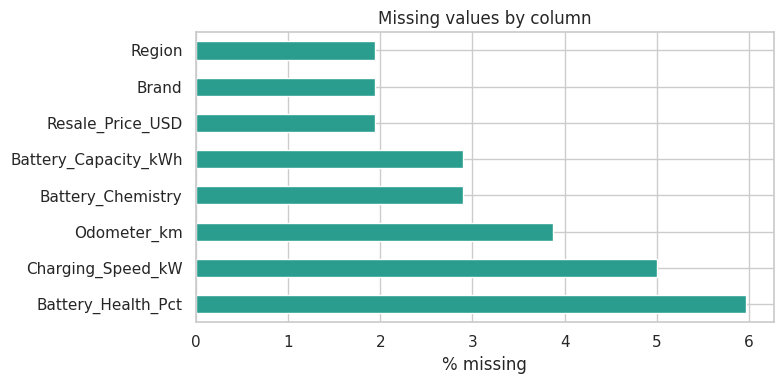

In [4]:
miss = df.isna().sum().sort_values(ascending=False)
miss_pct = (miss / len(df) * 100).round(2)
print(pd.DataFrame({"missing": miss, "pct": miss_pct})[miss > 0])

fig, ax = plt.subplots(figsize=(8, 4))
miss_pct[miss_pct > 0].plot.barh(ax=ax, color="#2a9d8f")
ax.set_xlabel("% missing"); ax.set_title("Missing values by column")
plt.tight_layout(); plt.savefig("figures/01_missing_values.png", dpi=130); plt.show()

### 1.2 Target handling and imputation
* Rows **without a price** have no regression label. Imputing a *target* would teach the model our own guess, so those rows are dropped
  (a small, documented deviation from "impute pricing"; all *feature* columns are imputed as specified).
* Numerical features → **median** (robust to the 9,999,999 km outliers). Categorical → **mode**.

In [5]:
before = len(df)
df = df.dropna(subset=["Resale_Price_USD"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with missing target price.")

num_raw = ["Battery_Capacity_kWh", "Range_km", "Odometer_km", "Battery_Health_Pct", "Charging_Speed_kW"]
cat_raw = ["Brand", "Battery_Chemistry", "Region"]
for c in num_raw:
    df[c] = df[c].fillna(df[c].median())
for c in cat_raw:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Remaining nulls:", int(df.isna().sum().sum()))

Dropped 12 rows with missing target price.
Remaining nulls: 0


### 1.3 Outlier detection – IQR method
Bounds: `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. Flagged values are **winsorised (capped)** to the bounds rather than dropped, so no listing is lost.

             feature    lower    upper  n_outliers    max_value
         Odometer_km -51610.6 149038.4          27 9.999999e+06
   Charging_Speed_kW    -16.5    243.5           4 9.000000e+02
    Resale_Price_USD  -4428.6  59720.4          12 2.843081e+05
Battery_Capacity_kWh     13.0    109.0           0 9.900000e+01
  Battery_Health_Pct     76.7    108.4          20 1.000000e+02
            Range_km     33.2    731.2           0 7.070000e+02


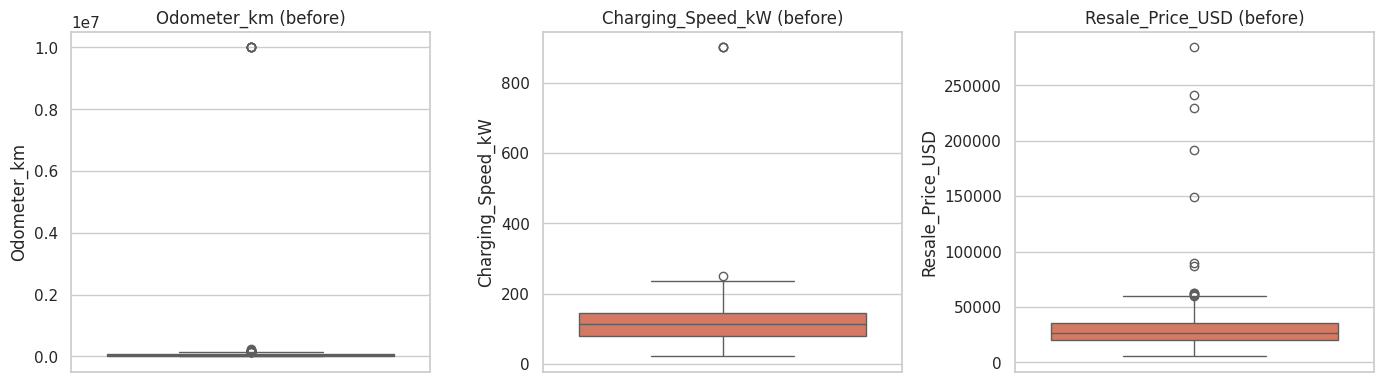

In [6]:
iqr_cols = ["Odometer_km", "Charging_Speed_kW", "Resale_Price_USD", "Battery_Capacity_kWh", "Battery_Health_Pct", "Range_km"]
rows = []
bounds = {}
for c in iqr_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[c] = (lo, hi)
    rows.append([c, round(lo, 1), round(hi, 1), int(((df[c] < lo) | (df[c] > hi)).sum()), df[c].max()])
print(pd.DataFrame(rows, columns=["feature", "lower", "upper", "n_outliers", "max_value"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Odometer_km", "Charging_Speed_kW", "Resale_Price_USD"]):
    sns.boxplot(y=df[c], ax=ax, color="#e76f51"); ax.set_title(f"{c} (before)")
plt.tight_layout(); plt.savefig("figures/02_outliers_before.png", dpi=130); plt.show()

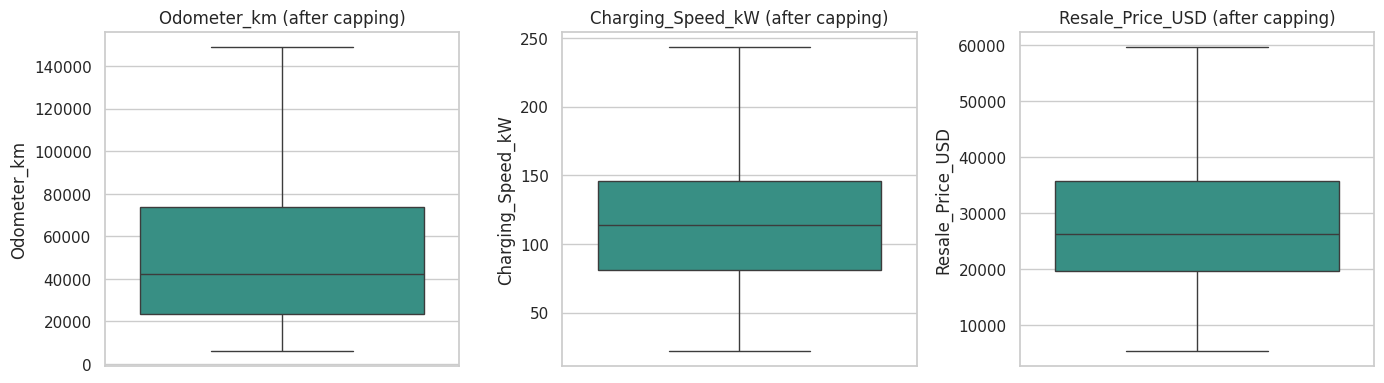

Max odometer now: 149038.375 | Max price now: 59720.375


In [7]:
df_clean = df.copy()
for c, (lo, hi) in bounds.items():
    df_clean[c] = df_clean[c].clip(lo, hi)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Odometer_km", "Charging_Speed_kW", "Resale_Price_USD"]):
    sns.boxplot(y=df_clean[c], ax=ax, color="#2a9d8f"); ax.set_title(f"{c} (after capping)")
plt.tight_layout(); plt.savefig("figures/03_outliers_after.png", dpi=130); plt.show()
print("Max odometer now:", df_clean["Odometer_km"].max(), "| Max price now:", df_clean["Resale_Price_USD"].max())

### 1.4 EDA on the cleaned data

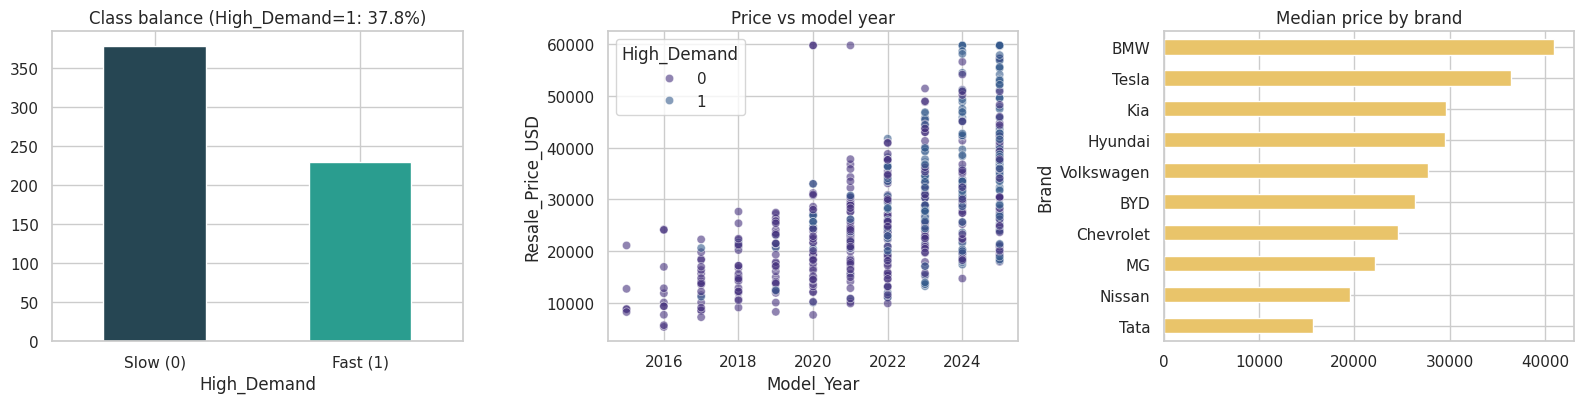

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
df_clean["High_Demand"].value_counts().sort_index().plot.bar(ax=axes[0], color=["#264653", "#2a9d8f"])
axes[0].set_title(f"Class balance (High_Demand=1: {df_clean.High_Demand.mean():.1%})"); axes[0].set_xticklabels(["Slow (0)", "Fast (1)"], rotation=0)
sns.scatterplot(data=df_clean, x="Model_Year", y="Resale_Price_USD", hue="High_Demand", alpha=.6, ax=axes[1])
axes[1].set_title("Price vs model year")
df_clean.groupby("Brand")["Resale_Price_USD"].median().sort_values().plot.barh(ax=axes[2], color="#e9c46a")
axes[2].set_title("Median price by brand")
plt.tight_layout(); plt.savefig("figures/04_eda.png", dpi=130); plt.show()

# Module 2 – Feature Engineering, Encoding & Scaling
### 2.1 Domain-driven features
* **Vehicle_Age** = 2026 − Model_Year
* **Energy_Efficiency_Index** = (Range_km / Battery_kWh) / (1 + Age) – range delivered per kWh, penalised for age
* **Battery_Degradation_Per_Year** = (100 − Battery_Health_%) / Age
* **Km_Per_Year** = Odometer / Age – usage intensity
* **Effective_Range_km** = Range × Battery_Health – today's real-world range

In [9]:
df_fe = df_clean.copy()
df_fe["Vehicle_Age"] = 2026 - df_fe["Model_Year"]
df_fe["Energy_Efficiency_Index"] = (df_fe["Range_km"] / df_fe["Battery_Capacity_kWh"]) / (1 + df_fe["Vehicle_Age"])
df_fe["Battery_Degradation_Per_Year"] = (100 - df_fe["Battery_Health_Pct"]) / df_fe["Vehicle_Age"].clip(lower=1)
df_fe["Km_Per_Year"] = df_fe["Odometer_km"] / df_fe["Vehicle_Age"].clip(lower=1)
df_fe["Effective_Range_km"] = df_fe["Range_km"] * df_fe["Battery_Health_Pct"] / 100
df_fe[["Vehicle_Age", "Energy_Efficiency_Index", "Battery_Degradation_Per_Year", "Km_Per_Year", "Effective_Range_km"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Vehicle_Age,608.0,3.87,2.45,1.00,2.00,3.00,5.00,11.00
Energy_Efficiency_Index,608.0,1.68,0.89,0.41,0.99,1.43,2.20,4.52
Battery_Degradation_Per_Year,608.0,2.12,0.96,0.00,1.70,2.20,2.60,7.00
Km_Per_Year,608.0,14453.52,8390.87,4718.89,9981.25,14091.38,17443.41,149038.38
Effective_Range_km,608.0,352.72,113.70,113.79,272.26,358.06,431.89,707.00


### 2.2 Encoding + scaling
* **One-Hot Encoding** for `Brand`, `Battery_Chemistry`, `Region`.
* **Z-score standardisation** (`StandardScaler`) for every continuous feature.

Both live inside a `ColumnTransformer` that is part of every model `Pipeline`, so the scaler is *fit on training folds only* – no data leakage in cross-validation.

In [10]:
NUM_FEATS = ["Vehicle_Age", "Battery_Capacity_kWh", "Range_km", "Odometer_km", "Battery_Health_Pct", "Charging_Speed_kW",
             "Energy_Efficiency_Index", "Battery_Degradation_Per_Year", "Km_Per_Year", "Effective_Range_km"]
CAT_FEATS = ["Brand", "Battery_Chemistry", "Region"]

def make_preprocessor(num_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS)])

# Classification may use the asking price as a signal; regression must NOT (it is the target).
NUM_CLF = NUM_FEATS + ["Resale_Price_USD"]
NUM_REG = NUM_FEATS

X_clf, y_clf = df_fe[NUM_CLF + CAT_FEATS], df_fe["High_Demand"]
X_reg, y_reg = df_fe[NUM_REG + CAT_FEATS], df_fe["Resale_Price_USD"]

# Demonstration only (fit on all data): verify scaling gives mean≈0, std≈1 and see the encoded width
demo = make_preprocessor(NUM_CLF).fit(X_clf)
Xd = pd.DataFrame(demo.transform(X_clf), columns=demo.get_feature_names_out())
print("Encoded feature matrix:", Xd.shape)
Xd.filter(like="num__").agg(["mean", "std"]).T.round(3)

Encoded feature matrix: (608, 28)


,mean,std
num__Vehicle_Age,-0.0,1.001
num__Battery_Capacity_kWh,-0.0,1.001
num__Range_km,0.0,1.001
num__Odometer_km,0.0,1.001
num__Battery_Health_Pct,0.0,1.001
num__Charging_Speed_kW,0.0,1.001
num__Energy_Efficiency_Index,-0.0,1.001
num__Battery_Degradation_Per_Year,0.0,1.001
num__Km_Per_Year,0.0,1.001
num__Effective_Range_km,0.0,1.001


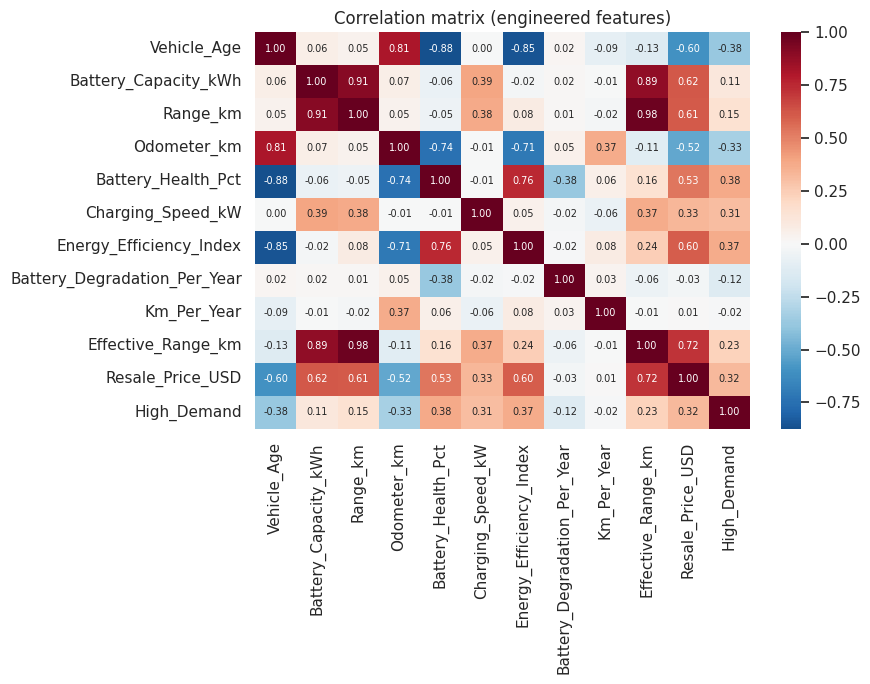

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df_fe[NUM_CLF + ["High_Demand"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation matrix (engineered features)")
plt.tight_layout(); plt.savefig("figures/05_correlation.png", dpi=130); plt.show()

# Module 3 – Feature Selection & Validation Setup
### 3.1 Recursive Feature Elimination (RFE)
RFE repeatedly fits an estimator and drops the weakest feature. Classification uses Logistic Regression; regression uses Linear Regression
(coefficients are comparable because inputs are standardised).

In [12]:
N_KEEP = 12

def rfe_table(X, y, estimator, num_cols, k=N_KEEP):
    pre = make_preprocessor(num_cols).fit(X)
    Xt = pre.transform(X); names = pre.get_feature_names_out()
    r = RFE(estimator, n_features_to_select=k).fit(Xt, y)
    return pd.DataFrame({"feature": names, "selected": r.support_, "rank": r.ranking_}).sort_values("rank")

rfe_clf = rfe_table(X_clf, y_clf, LogisticRegression(max_iter=2000), NUM_CLF)
rfe_reg = rfe_table(X_reg, y_reg, LinearRegression(), NUM_REG)
print("=== Classification – selected features ===");  print(rfe_clf[rfe_clf.selected].feature.tolist())
print("\n=== Regression – selected features ===");    print(rfe_reg[rfe_reg.selected].feature.tolist())
print("\nDiscarded (clf):", rfe_clf[~rfe_clf.selected].feature.tolist())

=== Classification – selected features ===
['num__Vehicle_Age', 'num__Battery_Health_Pct', 'num__Charging_Speed_kW', 'cat__Brand_Chevrolet', 'cat__Brand_BYD', 'cat__Brand_BMW', 'num__Resale_Price_USD', 'num__Effective_Range_km', 'cat__Region_Asia', 'cat__Brand_Volkswagen', 'cat__Brand_Tesla', 'cat__Brand_Nissan']

=== Regression – selected features ===
['num__Vehicle_Age', 'num__Battery_Capacity_kWh', 'num__Range_km', 'num__Battery_Health_Pct', 'num__Energy_Efficiency_Index', 'cat__Brand_MG', 'cat__Brand_BMW', 'num__Effective_Range_km', 'cat__Region_Asia', 'cat__Brand_Tesla', 'cat__Brand_Tata', 'cat__Brand_Nissan']

Discarded (clf): ['cat__Brand_Tata', 'cat__Brand_MG', 'cat__Battery_Chemistry_NMC', 'cat__Brand_Hyundai', 'cat__Brand_Kia', 'num__Odometer_km', 'num__Energy_Efficiency_Index', 'num__Battery_Capacity_kWh', 'cat__Battery_Chemistry_NCA', 'cat__Region_North America', 'cat__Region_Europe', 'cat__Region_Middle East', 'cat__Battery_Chemistry_LFP', 'num__Battery_Degradation_Per_Yea

### 3.2 Validation blueprint
* **Classification:** `StratifiedKFold(5)` on `High_Demand` – every fold keeps the ~38 % positive rate.
* **Regression:** price is continuous, so we stratify on **price quartile bins** to keep every fold's price distribution comparable.

RFE is placed *inside* each pipeline, so feature selection is re-done on each training fold (no selection leakage).

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf_cv = list(skf.split(X_clf, y_clf))
price_bins = pd.qcut(y_reg, 4, labels=False)
reg_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_reg, price_bins))

print("Fold | n_train n_test | positive rate (test)")
for i, (tr, te) in enumerate(clf_cv, 1):
    print(f"  {i}  |  {len(tr):4d}   {len(te):4d}  |  {y_clf.iloc[te].mean():.3f}")
print(f"overall positive rate: {y_clf.mean():.3f}")

Fold | n_train n_test | positive rate (test)
  1  |   486    122  |  0.377
  2  |   486    122  |  0.377
  3  |   486    122  |  0.377
  4  |   487    121  |  0.380
  5  |   487    121  |  0.380
overall positive rate: 0.378


# Module 4 – Baselines & Hyperparameter Tuning
### 4.1 Pipeline factory
`preprocess → RFE → model`. Baselines (Logistic Regression, KNN, SVM) use sensible default settings to set the benchmark.

In [14]:
def build(task, model, k=N_KEEP):
    num = NUM_CLF if task == "clf" else NUM_REG
    est = LogisticRegression(max_iter=2000) if task == "clf" else LinearRegression()
    return Pipeline([("prep", make_preprocessor(num)),
                     ("rfe", RFE(est, n_features_to_select=k)),
                     ("model", model)])

clf_scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
reg_scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def run_cv(pipe, X, y, cv, scoring):
    s = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1)
    out = {}
    for k in scoring:
        v = s[f"test_{k}"]
        if k in ("rmse", "mae"): v = -v
        out[k + "_mean"], out[k + "_std"] = v.mean(), v.std()
    return out

### 4.2 Baseline models – Classification

In [15]:
clf_results = {}
baselines_clf = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0),
}
for name, m in baselines_clf.items():
    clf_results[name] = run_cv(build("clf", m), X_clf, y_clf, clf_cv, clf_scoring)
pd.DataFrame(clf_results).T.filter(like="_mean").round(4)

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean
Logistic Regression,0.7319,0.6604,0.6130,0.6330,0.8172
KNN,0.7007,0.6192,0.5826,0.5954,0.7445
SVM (RBF),0.7286,0.6785,0.5391,0.6004,0.7934


### 4.3 Baseline models – Regression

In [16]:
reg_results = {}
baselines_reg = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=7),
    "SVR (RBF)": SVR(kernel="rbf", C=50000, epsilon=500, gamma="scale"),
}
for name, m in baselines_reg.items():
    reg_results[name] = run_cv(build("reg", m), X_reg, y_reg, reg_cv, reg_scoring)
pd.DataFrame(reg_results).T.filter(like="_mean").round(3)

,r2_mean,rmse_mean,mae_mean
Linear Regression,0.891,3897.285,2444.338
KNN,0.864,4389.380,2891.627
SVR (RBF),0.905,3609.696,2137.508


# Module 5 – Ensembles with RandomizedSearchCV & Final Evaluation
**Bagging:** Random Forest · **Boosting:** AdaBoost.

Hyper-parameters (tree depth, estimator count, learning rate, …) are tuned with `RandomizedSearchCV`.
To report an **unbiased** score, tuning is *nested*: the search runs inside each outer CV training fold and is scored on the untouched outer test fold.

In [17]:
N_ITER, INNER = 6, 3

rf_space = {"model__n_estimators": randint(100, 250), "model__max_depth": [3, 5, 8, 12, None],
            "model__min_samples_split": randint(2, 12), "model__min_samples_leaf": randint(1, 6),
            "model__max_features": ["sqrt", "log2", None]}

ada_clf_space = {"model__n_estimators": randint(50, 200), "model__learning_rate": loguniform(0.01, 1.5),
                 "model__estimator": [DecisionTreeClassifier(max_depth=d) for d in (1, 2, 3)]}
ada_reg_space = {"model__n_estimators": randint(50, 300), "model__learning_rate": loguniform(0.01, 1.5),
                 "model__loss": ["linear", "square", "exponential"],
                 "model__estimator": [DecisionTreeRegressor(max_depth=d) for d in (3, 5, 7)]}

def searcher(task, model, space, cv_inner, scoring):
    return RandomizedSearchCV(build(task, model), space, n_iter=N_ITER, cv=cv_inner,
                              scoring=scoring, random_state=SEED, n_jobs=1)

inner_clf = StratifiedKFold(INNER, shuffle=True, random_state=SEED)
inner_reg = KFold(INNER, shuffle=True, random_state=SEED)

ens_clf = {
    "Random Forest (bagging)": searcher("clf", RandomForestClassifier(random_state=SEED), rf_space, inner_clf, "f1"),
    "AdaBoost (boosting)": searcher("clf", AdaBoostClassifier(random_state=SEED), ada_clf_space, inner_clf, "f1"),
}
for name, s in ens_clf.items():
    clf_results[name] = run_cv(s, X_clf, y_clf, clf_cv, clf_scoring)

ens_reg = {
    "Random Forest (bagging)": searcher("reg", RandomForestRegressor(random_state=SEED), rf_space, inner_reg, "r2"),
    "AdaBoost (boosting)": searcher("reg", AdaBoostRegressor(random_state=SEED), ada_reg_space, inner_reg, "r2"),
}
for name, s in ens_reg.items():
    reg_results[name] = run_cv(s, X_reg, y_reg, reg_cv, reg_scoring)
print("Ensembles done.")

Ensembles done.


### 5.1 Model comparison – Classification (5-fold Stratified CV, mean ± std)

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.732 ± 0.025,0.66 ± 0.044,0.613 ± 0.059,0.633 ± 0.033,0.817 ± 0.021
KNN,0.701 ± 0.032,0.619 ± 0.063,0.583 ± 0.056,0.595 ± 0.028,0.745 ± 0.032
SVM (RBF),0.729 ± 0.022,0.678 ± 0.039,0.539 ± 0.032,0.6 ± 0.031,0.793 ± 0.02
Random Forest (bagging),0.727 ± 0.027,0.665 ± 0.051,0.57 ± 0.042,0.612 ± 0.035,0.782 ± 0.026
AdaBoost (boosting),0.704 ± 0.031,0.618 ± 0.048,0.583 ± 0.069,0.597 ± 0.045,0.778 ± 0.028


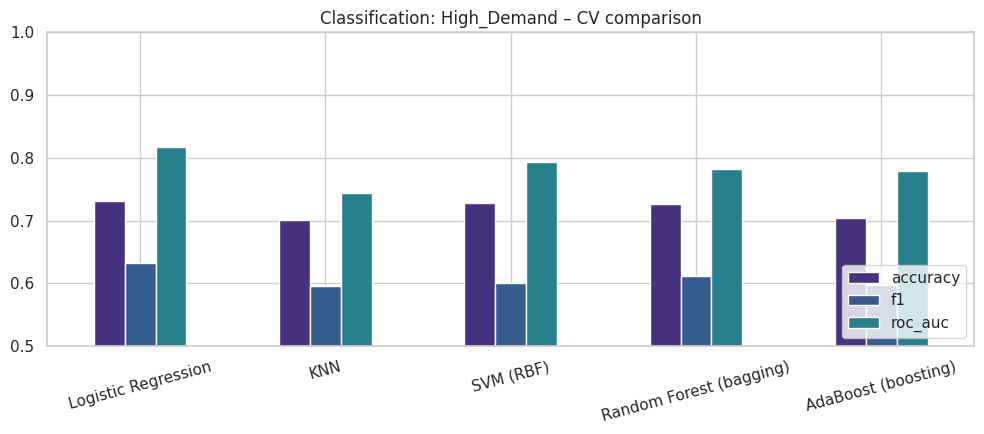

In [18]:
def fmt(res, keys):
    d = pd.DataFrame(res).T
    return pd.DataFrame({k: d[k + "_mean"].round(3).astype(str) + " ± " + d[k + "_std"].round(3).astype(str) for k in keys})

clf_tbl = pd.DataFrame(clf_results).T
display(fmt(clf_results, list(clf_scoring)))

fig, ax = plt.subplots(figsize=(10, 4.5))
clf_tbl[[f"{m}_mean" for m in ["accuracy", "f1", "roc_auc"]]].rename(columns=lambda c: c.replace("_mean", "")).plot.bar(ax=ax, rot=15)
ax.set_ylim(0.5, 1.0); ax.set_title("Classification: High_Demand – CV comparison"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/06_clf_comparison.png", dpi=130); plt.show()

### 5.2 Model comparison – Regression

,r2,rmse,mae
Linear Regression,0.891 ± 0.047,3897.285 ± 922.058,2444.338 ± 292.995
KNN,0.864 ± 0.049,4389.38 ± 929.196,2891.627 ± 310.857
SVR (RBF),0.905 ± 0.05,3609.696 ± 1016.288,2137.508 ± 272.351
Random Forest (bagging),0.861 ± 0.047,4444.072 ± 865.338,2991.63 ± 138.533
AdaBoost (boosting),0.86 ± 0.049,4462.765 ± 876.466,2919.417 ± 189.797


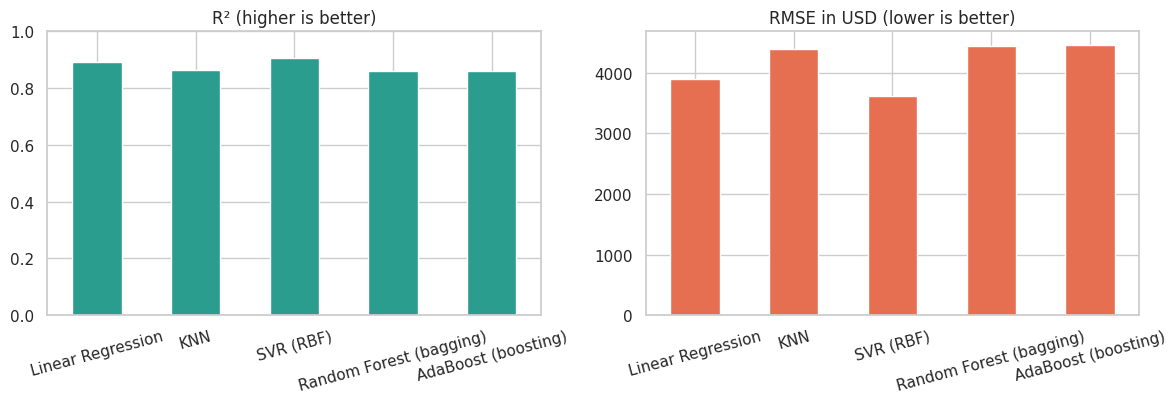

In [19]:
reg_tbl = pd.DataFrame(reg_results).T
display(fmt(reg_results, list(reg_scoring)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
reg_tbl["r2_mean"].plot.bar(ax=axes[0], rot=15, color="#2a9d8f"); axes[0].set_title("R² (higher is better)"); axes[0].set_ylim(0, 1)
reg_tbl["rmse_mean"].plot.bar(ax=axes[1], rot=15, color="#e76f51"); axes[1].set_title("RMSE in USD (lower is better)")
plt.tight_layout(); plt.savefig("figures/07_reg_comparison.png", dpi=130); plt.show()

### 5.3 Final models – tuned on a training split and tested on a 20 % hold-out set

Best classifier by CV F1: Logistic Regression
              precision    recall  f1-score   support

   Slow sale       0.71      0.86      0.78        76
   Fast sale       0.65      0.43      0.52        46

    accuracy                           0.70       122
   macro avg       0.68      0.65      0.65       122
weighted avg       0.69      0.70      0.68       122



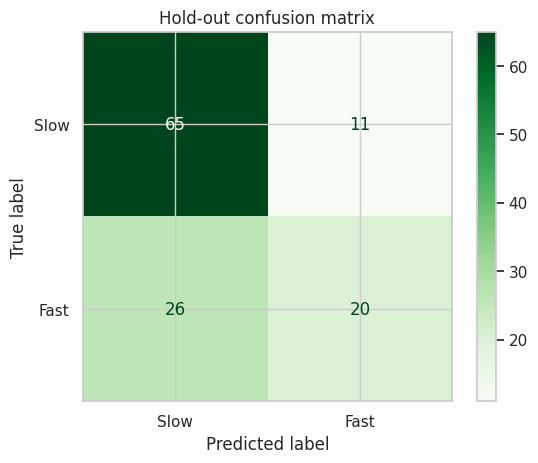

In [20]:
Xtr, Xte, ytr, yte = train_test_split(X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=SEED)
best_clf_name = clf_tbl["f1_mean"].idxmax()
cand_clf = {**{n: build("clf", m) for n, m in baselines_clf.items()}, **ens_clf}
final_clf_search = cand_clf[best_clf_name]
final_clf_search.fit(Xtr, ytr)
pred = final_clf_search.predict(Xte)
rf_clf_search = ens_clf["Random Forest (bagging)"]
if rf_clf_search is not final_clf_search: rf_clf_search.fit(Xtr, ytr)

print(f"Best classifier by CV F1: {best_clf_name}")
if hasattr(final_clf_search, "best_params_"):
    print("Best hyper-parameters:", {k.replace('model__', ''): v for k, v in final_clf_search.best_params_.items()})
print(classification_report(yte, pred, target_names=["Slow sale", "Fast sale"]))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["Slow", "Fast"]).plot(cmap="Greens")
plt.title("Hold-out confusion matrix"); plt.savefig("figures/08_confusion_matrix.png", dpi=130); plt.show()

Best regressor by CV R²: SVR (RBF)
Hold-out  R² = 0.949 | RMSE = $2,743 | MAE = $2,014


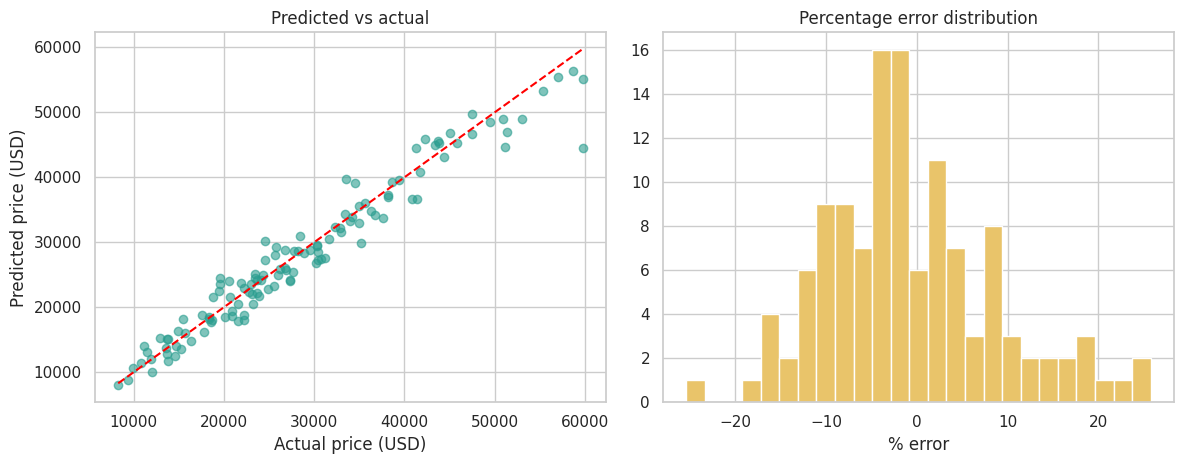

In [21]:
bins_tr = pd.qcut(y_reg, 4, labels=False)
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X_reg, y_reg, test_size=0.2, stratify=bins_tr, random_state=SEED)
best_reg_name = reg_tbl["r2_mean"].idxmax()
cand_reg = {**{n: build("reg", m) for n, m in baselines_reg.items()}, **ens_reg}
final_reg_search = cand_reg[best_reg_name]
final_reg_search.fit(Xtr_r, ytr_r)
pr = final_reg_search.predict(Xte_r)
rf_reg_search = ens_reg["Random Forest (bagging)"]
if rf_reg_search is not final_reg_search: rf_reg_search.fit(Xtr_r, ytr_r)

print(f"Best regressor by CV R²: {best_reg_name}")
if hasattr(final_reg_search, "best_params_"):
    print("Best hyper-parameters:", {k.replace('model__', ''): v for k, v in final_reg_search.best_params_.items()})
print(f"Hold-out  R² = {r2_score(yte_r, pr):.3f} | RMSE = ${np.sqrt(mean_squared_error(yte_r, pr)):,.0f} | MAE = ${mean_absolute_error(yte_r, pr):,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(yte_r, pr, alpha=.6, color="#2a9d8f"); lim = [yte_r.min(), yte_r.max()]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Actual price (USD)"); axes[0].set_ylabel("Predicted price (USD)"); axes[0].set_title("Predicted vs actual")
axes[1].hist((pr - yte_r) / yte_r * 100, bins=25, color="#e9c46a"); axes[1].set_title("Percentage error distribution"); axes[1].set_xlabel("% error")
plt.tight_layout(); plt.savefig("figures/09_regression_fit.png", dpi=130); plt.show()

### 5.4 What drives price and demand? (feature importances of the tuned Random Forests)

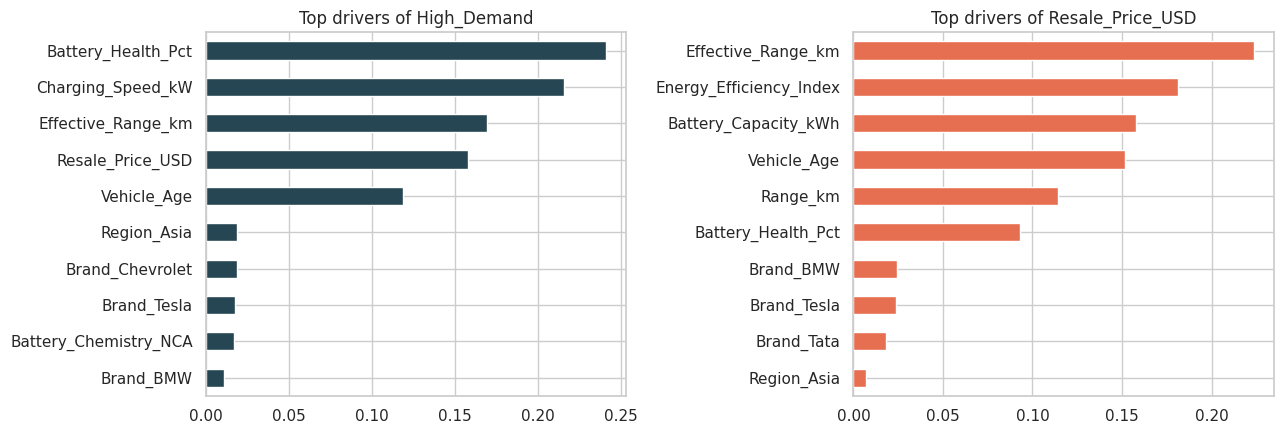

In [22]:
def importances(search, label):
    pipe = search.best_estimator_
    names = pipe.named_steps["prep"].get_feature_names_out()[pipe.named_steps["rfe"].support_]
    m = pipe.named_steps["model"]
    return pd.Series(m.feature_importances_, index=[n.split("__")[1] for n in names]).sort_values().tail(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
importances(rf_clf_search, "clf").plot.barh(ax=axes[0], color="#264653"); axes[0].set_title("Top drivers of High_Demand")
importances(rf_reg_search, "reg").plot.barh(ax=axes[1], color="#e76f51"); axes[1].set_title("Top drivers of Resale_Price_USD")
plt.tight_layout(); plt.savefig("figures/10_importances.png", dpi=130); plt.show()

## Final Recommendation

In [23]:
best_c = clf_tbl["f1_mean"].idxmax(); best_r = reg_tbl["r2_mean"].idxmax()
print("=" * 70)
print(f"CLASSIFICATION  → {best_c}")
print(f"   CV  F1 = {clf_tbl.loc[best_c,'f1_mean']:.3f} | ROC-AUC = {clf_tbl.loc[best_c,'roc_auc_mean']:.3f} | Accuracy = {clf_tbl.loc[best_c,'accuracy_mean']:.3f}")
print(f"REGRESSION      → {best_r}")
print(f"   CV  R² = {reg_tbl.loc[best_r,'r2_mean']:.3f} | RMSE = ${reg_tbl.loc[best_r,'rmse_mean']:,.0f} | MAE = ${reg_tbl.loc[best_r,'mae_mean']:,.0f}")
print("=" * 70)
df_fe.to_csv("ecodrive_cleaned_features.csv", index=False)
pd.concat([fmt(clf_results, list(clf_scoring)).add_prefix("clf_")], axis=1).to_csv("classification_results.csv")
fmt(reg_results, list(reg_scoring)).add_prefix("reg_").to_csv("regression_results.csv")

CLASSIFICATION  → Logistic Regression
   CV  F1 = 0.633 | ROC-AUC = 0.817 | Accuracy = 0.732
REGRESSION      → SVR (RBF)
   CV  R² = 0.905 | RMSE = $3,610 | MAE = $2,138


## Conclusions & Business Interpretation
See the printed recommendation above and the accompanying `EcoDrive_Report.md` for a written summary of findings, limitations and next steps.